# MapKW: Graph Theory Applied to Urban Route Optimization

### Exploring shortest-path algorithms across the Kitchener-Waterloo road network

**Tech Stack:** Python · OSMnx · NetworkX · GeoPandas · Pandas · Folium · ipywidgets · Tableau Public

Author: Vishal Srikanth

## Project Overview

How does a navigation system decide which route to recommend? Is the shortest route always the fastest? And how much computational effort can be saved by choosing a more efficient search algorithm?

I built **MapKW** to explore these questions using graph theory and the real-world road network of the Regional Municipality of Waterloo, Ontario.

The project models drivable roads as a weighted, directed graph and applies several pathfinding algorithms to identify optimal routes, compare their performance, and generate alternative journeys.

Rather than stopping at a single shortest-path calculation, I wanted to build a complete workflow: acquiring geographic data, constructing a graph, evaluating algorithms, visualizing routes, and preparing a dataset for an interactive Tableau dashboard.

### Project Objectives

1. **Model a real road network:** Convert OpenStreetMap road data into a directed, weighted graph.
2. **Implement and compare search algorithms:** Evaluate Dijkstra's, A*, Bidirectional Dijkstra, and Breadth-First Search.
3. **Explore alternative routing:** Use Yen's K-shortest paths algorithm to identify multiple candidate routes.
4. **Evaluate route trade-offs:** Compare estimated travel time, physical distance, and path complexity.
5. **Build an interactive prototype:** Allow users to select local landmarks and visualize route alternatives.
6. **Prepare a scalable visualization dataset:** Precompute routes between regional landmarks for Tableau Public.

### Central Question

> How can graph theory help identify efficient driving routes, and what trade-offs emerge between route optimality, computational efficiency, and alternative-route selection?

**Scope:** This project focuses on static, estimated driving conditions. It does not incorporate live traffic, road closures, weather, or real-time navigation data.

## Technical Approach

MapKW follows a pipeline that connects graph theory with geographic data engineering.

**1. Network Acquisition and Preprocessing**

Download the regional drivable road network, project its coordinates, consolidate nearby intersections, and assign estimated travel-time weights.

**2. Shortest-Path Search**

Implement Dijkstra's algorithm, A* search, Bidirectional Dijkstra, and BFS to compare different approaches to graph traversal.

**3. Alternative Route Generation**

Use Yen's K-shortest paths algorithm to generate multiple candidate routes and calculate their comparative metrics.

**4. Interactive Route Exploration**

Build a Folium-based map with landmark selectors to inspect optimal and alternative routes.

**5. Algorithm Benchmarking**

Compare execution time, estimated route cost, and path length to understand the practical differences between algorithms.

**6. Tableau Data Preparation**

Generate a precomputed routing dataset across 47 regional landmarks and export geographic coordinates and route metrics for dashboard development.

### How to Read This Notebook

Each major section introduces the relevant graph theory concepts, explains the implementation approach, and interprets the resulting outputs.

The notebook begins with a single origin-destination example before expanding into a regional batch-processing workflow. This allows the algorithms to be understood and evaluated on a smaller problem before being applied at scale.

# 1. Building the Road Network Graph

## 1.1 Representing Roads as a Graph

Before applying any routing algorithms, I need to represent the road network as a mathematical graph.

A graph is defined as:

$$
G=(V,E)
$$

Where:

- $V$ is the set of vertices (nodes).
- $E$ is the set of edges connecting those vertices.

For MapKW, nodes represent road-network junctions and endpoints, while edges represent traversable road segments.

The road network is represented using a **directed multigraph**, implemented as a NetworkX `MultiDiGraph`.

This is important for two reasons:

- **Directed edges:** Road networks contain one-way streets and directional travel restrictions. A connection from node $u$ to node $v$ does not necessarily imply that travel is permitted in the reverse direction.
- **Multiple edges:** Two nodes may be connected by more than one road segment, each potentially having different attributes.

Each edge can store properties such as distance, speed, and estimated travel time.

For the routing algorithms, the graph becomes:

$$
G=(V,E,w)
$$

Where $w:E\rightarrow\mathbb{R}_{\geq0}$ assigns a non-negative cost to each edge.

In this project, the primary optimization objective is **minimum estimated travel time**, rather than minimum physical distance.

### Data Source

Citation:

*Boeing, G. (2025). Modeling and Analyzing Urban Networks and Amenities with OSMnx. Geographical Analysis 57 (4), 567-577. doi:10.1111/gean.70009*

I use OSMnx to retrieve the drivable street network for the Regional Municipality of Waterloo from OpenStreetMap.

The `drive` network type focuses the graph on roads intended for motor-vehicle travel, making it more appropriate for driving-route analysis than an unrestricted pedestrian or cycling network.

In [56]:
# Checkpoint 1.1: Download Regional Municipality of Waterloo Drivable Street Network
import osmnx as ox
import networkx as nx

# Configure OSMnx settings
ox.settings.use_cache = True
ox.settings.log_console = True

# Define the broader regional query to include both Waterloo and Kitchener
place_query = "Regional Municipality of Waterloo, Ontario, Canada"

print(f"Downloading street network for: {place_query}...")
G = ox.graph_from_place(place_query, network_type="drive")

print("\n--- Graph Download Complete ---")
print(f"Total Nodes (Intersections): {len(G.nodes):,}")
print(f"Total Edges (Street Segments): {len(G.edges):,}")
print(f"Graph Data Structure Type: {type(G)}")


--- Graph Download Complete ---
Total Nodes (Intersections): 12,024
Total Edges (Street Segments): 32,542
Graph Data Structure Type: <class 'networkx.classes.multidigraph.MultiDiGraph'>


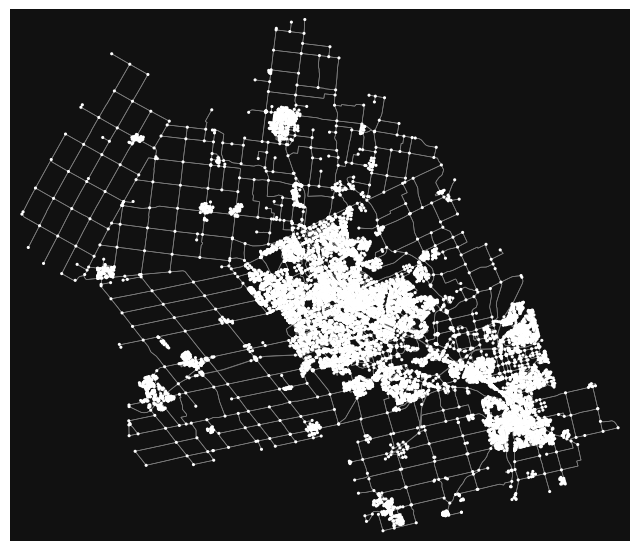

In [57]:
fig, ax = ox.plot_graph(G, node_size=5, edge_color="gray", edge_linewidth=0.5)

### 1.2 Initial Network Inspection

The downloaded road network contains:

| Metric | Value |
|---|---:|
| Nodes | 12,024 |
| Directed edges | 32,542 |
| Graph type | `MultiDiGraph` |

The first visualization provides a structural overview of the region's road connectivity.

Dense clusters of nodes and edges correspond to areas with more interconnected road infrastructure, while the less dense portions represent areas with fewer mapped road connections.

An important distinction is that graph nodes are not necessarily equivalent to physical intersections. They may also represent road endpoints and other structural features.

At this stage, the graph describes **where driving is possible**, but it does not yet provide the final travel-time model needed for routing.

The next step is to prepare the graph for weighted shortest-path calculations.

## 1.3 Preparing the Graph for Route Optimization

Raw geographic data needs additional processing before it can be used reliably for spatial calculations and routing.

The preprocessing workflow consists of four main operations.

### A. Coordinate Reference System (CRS) Projection

OpenStreetMap geographic coordinates are generally represented using latitude and longitude in degrees.

However, geometric distance calculations require an appropriate projected coordinate system.

I use OSMnx to project the graph into a local metric coordinate reference system, allowing node coordinates to be measured in metres.

This is especially important for the A* heuristic, which estimates the straight-line distance between two nodes.

### B. Graph Simplification and Intersection Consolidation

OSMnx can simplify graph topology by removing unnecessary intermediate nodes while preserving road connectivity and geometry.

The downloaded graph is already simplified, so the notebook does not repeat this operation.

I then consolidate nearby intersections using a 15-metre tolerance.

This helps represent complex intersections more compactly, although the choice of tolerance can affect network topology and should be treated as a modelling parameter.

### C. Speed Estimation

Not every OpenStreetMap road segment has a recorded speed limit.

To address missing values, I use OSMnx's edge-speed estimation functionality. The resulting speed values combine available road attributes with imputed estimates where required.

These values are useful for a static routing model, but should not be interpreted as observed vehicle speeds or live traffic conditions.

### D. Travel-Time Edge Weights

For an edge $e$, estimated travel time is calculated as:

$$
t_e=\frac{d_e}{v_e}
$$

Where:

- $t_e$ = estimated travel time in seconds
- $d_e$ = edge length in metres
- $v_e$ = estimated travel speed in metres per second

When speed is expressed in kilometres per hour:

$$
t_e=\frac{3.6d_e}{v_{e,\text{km/h}}}
$$

The total cost of a route $P$ is:

$$
T(P)=\sum_{e\in P}t_e
$$

The optimization problem is therefore:

$$
P^*=\arg\min_{P\in\mathcal{P}(s,t)}T(P)
$$

Where $\mathcal{P}(s,t)$ represents the set of valid directed paths from origin $s$ to destination $t$.

This weighted graph is the foundation for all subsequent route calculations.

In [58]:
# Checkpoint 1.2: Project Graph, Simplify, Consolidate Intersections, and Impute Travel Times
import osmnx as ox

print(f"Initial graph node count: {len(G.nodes):,}")
print(f"Initial graph edge count: {len(G.edges):,}")

# Step 1: Project the graph to a local CRS (meters instead of lat/lon degrees)
print("Projecting graph to local UTM coordinate system...")
G_proj = ox.project_graph(G)

# Step 2: Simplify graph topology (remove redundant shape nodes)
if not G_proj.graph.get("simplified", False):
    print("Simplifying graph topology...")
    G_simplified = ox.simplify_graph(G_proj)
else:
    print("Graph is already simplified.")
    G_simplified = G_proj

# Step 3: Consolidate complex intersections (tolerance = 15 meters)
print("Consolidating intersections...")
G_consolidated = ox.consolidate_intersections(G_simplified, tolerance=15, rebuild_graph=True)

# Step 4: Add imputed speed limits where tags are missing
print("Imputing edge speeds...")
G_speed = ox.add_edge_speeds(G_consolidated)

# Step 5: Calculate travel time weights (length / speed) for each edge
print("Calculating edge travel times...")
G_weighted = ox.add_edge_travel_times(G_speed)

print("\n--- Optimized Regional Graph Ready ---")
print(f"Final Simplified & Consolidated Nodes: {len(G_weighted.nodes):,}")
print(f"Final Simplified & Consolidated Edges: {len(G_weighted.edges):,}")

Initial graph node count: 12,024
Initial graph edge count: 32,542
Projecting graph to local UTM coordinate system...
Graph is already simplified.
Consolidating intersections...
Imputing edge speeds...
Calculating edge travel times...

--- Optimized Regional Graph Ready ---
Final Simplified & Consolidated Nodes: 9,442
Final Simplified & Consolidated Edges: 27,880


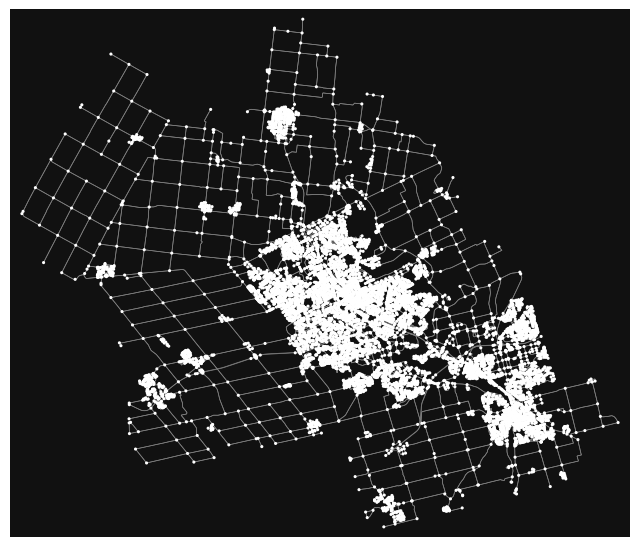

In [59]:
fig, ax = ox.plot_graph(G_weighted, node_size= 5, edge_color="gray", edge_linewidth=0.5)

### 1.4 Preprocessing Results

| Metric | Original Graph | Processed Graph |
|---|---:|---:|
| Nodes | 12,024 | 9,442 |
| Edges | 32,542 | 27,880 |

After preprocessing, the graph contains approximately **21.5% fewer nodes** and **14.3% fewer edges**.

This reduces the size of the graph used in subsequent routing calculations.

However, fewer nodes do not automatically imply a faster or more accurate routing system. Consolidating intersections changes the graph representation, and its effect on route quality would require additional validation.

The processed graph now contains the spatial coordinates and estimated travel-time weights required for weighted pathfinding.

**Next:** Compare different algorithms for finding a route through this network.

# 2. Shortest-Path Algorithms

## 2.1 Dijkstra's Algorithm vs. A* Search

The first comparison focuses on two weighted shortest-path algorithms: Dijkstra's algorithm and A* search.

Both attempt to find the minimum-cost route between an origin and destination, but they differ in how they prioritize the search.

### Dijkstra's Algorithm

Dijkstra's algorithm explores nodes in order of their lowest known accumulated cost from the source.

For a node $n$:

$$
f(n)=g(n)
$$

Where $g(n)$ is the best currently known travel cost from the origin to node $n$.

With non-negative edge weights, Dijkstra's algorithm guarantees an optimal shortest path.

It does not use information about the destination's geographic position to guide its exploration.

### A* Search

A* extends cost-based search by incorporating a heuristic estimate of the remaining cost:

$$
f(n)=g(n)+h(n)
$$

Where:

- $g(n)$ = accumulated travel cost from the origin
- $h(n)$ = estimated remaining cost to the destination
- $f(n)$ = estimated total route cost through node $n$

For MapKW, I use a Euclidean-distance heuristic based on projected node coordinates:

$$
d(n,t)=\sqrt{(x_t-x_n)^2+(y_t-y_n)^2}
$$

The distance is converted into estimated travel time:

$$
h(n)=\frac{d(n,t)}{v_{\max}}
$$

The implementation uses $v_{\max}=27.78$ m/s, approximately 100 km/h.

### Why the Heuristic Matters

A* can reduce unnecessary exploration by prioritizing nodes that appear closer to the destination in terms of estimated total cost.

For optimality, the heuristic must not overestimate the true remaining travel cost.

The 100 km/h assumption is intended to provide a conservative estimate, but its admissibility depends on the actual edge speeds and geometry in the processed graph. I have not independently verified that condition for every edge.

### Expected Complexity

For a typical priority-queue implementation of Dijkstra's algorithm:

$$
O((|V|+|E|)\log|V|)
$$

A* has no universal guarantee of outperforming Dijkstra. Its practical efficiency depends heavily on the quality of the heuristic and the graph structure.

The key question is whether A* can return the same minimum travel-time cost while exploring less of the network.

In [60]:

import networkx as nx
import time
import math

def run_dijkstra(G, source, target, weight='travel_time'):
    """Standard Dijkstra's Algorithm using NetworkX with execution timing."""
    start_time = time.time() #records timestamp at start of execution
    path = nx.shortest_path(G, source=source, target=target, weight=weight)
    length = nx.path_weight(G, path, weight=weight)
    exec_time = (time.time() - start_time) * 1000  # milliseconds
    return path, length, exec_time

def run_astar(G, source, target, weight='travel_time'):
    """A* Search using Euclidean heuristic on projected UTM meter coordinates."""
    start_time = time.time()
    
    def heuristic(u, v): #local function for A* to calculate priority score for every node
        # G is projected in UTM meters, x and y are flat Cartesian coordinates!
        x1, y1 = G.nodes[u]['x'], G.nodes[u]['y']
        x2, y2 = G.nodes[v]['x'], G.nodes[v]['y']
        
        # math.hypot converts the differences in x and y to straight-line Euclidean distance in meters
        dist_meters = math.hypot(x2 - x1, y2 - y1)
        
        # Convert distance (meters) to estimated travel time (seconds)
        # Using max highway speed (~100 km/h = 27.78 m/s) to guarantee admissibility
        max_speed_ms = 27.78 
        return dist_meters / max_speed_ms
    # NetworkX evaluates the priority queue using f(n) = g(n) + h(n)
    #to steer the search wavefront toward the target efficiently
    path = nx.astar_path(G, source=source, target=target, heuristic=heuristic, weight=weight)
    length = nx.path_weight(G, path, weight=weight)
    
    exec_time = (time.time() - start_time) * 1000  # milliseconds
    return path, length, exec_time


## 2.2 Test Route: Wilfrid Laurier University to Conestoga Mall

To compare the algorithms, I start with a single origin-destination pair:

- **Origin:** Wilfrid Laurier University
- **Destination:** Conestoga Mall

Using a fixed test case makes it easier to compare the outputs of different algorithms before expanding to additional locations.

### Converting Landmarks into Graph Nodes

Landmarks are initially defined using geographic latitude and longitude coordinates.

The road graph, however, uses projected coordinates measured in metres.

To connect these two representations, I:

1. Create a geographic point using the landmark coordinates.
2. Transform that point into the graph's projected CRS.
3. Find the nearest graph node using OSMnx.
4. Use the resulting node IDs as the routing origin and destination.

This process is known as **spatial snapping**.

It ensures that the pathfinding algorithms operate on valid graph nodes rather than arbitrary geographic coordinates.

One limitation is that the nearest node may not correspond exactly to a landmark's vehicle entrance. The calculated journey therefore represents travel between snapped road-network nodes, not necessarily a complete door-to-door journey.

In [61]:
# Testing Dijkstra's and A* algorithms from Laurier to Conestoga Mall (Robust Projected Lookup)
import osmnx as ox
import geopandas as gpd
from shapely.geometry import Point

# Landmark coordinates (Lat, Lon)
orig_coords = (43.4743, -80.5280) # Wilfrid Laurier University
dest_coords = (43.4978, -80.5263) # Conestoga Mall

# Function to find the nearest node in the projected graph for given lat/lon coordinates
# This ensures that the nearest node is found in the same coordinate system as the graph, avoiding projection errors.
#G_weightted is projected into UTM coordinates (meters) rather than degrees
#By wrapping the Lat/Lon point in a GeoDataFrame and projecting it, we ensure accurate nearest node lookup in UTM coordinates
#Using .to_crs(G.graph['crs])to mathematiclly project that single point to the exact local UTM metric coordinate
#it extracts the new projected X (easting) and Y (northing) coordinates in meters
#Then passes those meter coordinates into ox.distance.nearest_nodes to find the closest graph intersection node in G_weighted
def get_node_in_projected_graph(G, lat, lon):
    """Projects a lat/lon point to match the graph's UTM CRS and finds the nearest node."""
    # Create GeoDataFrame in lat/lon (EPSG:4326)
    pt = gpd.GeoDataFrame(geometry=[Point(lon, lat)], crs="EPSG:4326")
    # Project to the graph's CRS (meters)
    pt_proj = pt.to_crs(G.graph['crs'])
    x_proj, y_proj = pt_proj.geometry.x.iloc[0], pt_proj.geometry.y.iloc[0]
    # Find nearest node in the projected graph
    return ox.distance.nearest_nodes(G, X=x_proj, Y=y_proj)

# Get valid node IDs directly from G_weighted
#By calling the projection function for Laurier and Conestoga Mall,
#we obtain the closest graph intersection in G_weighted to serve as the source and target.
orig_node = get_node_in_projected_graph(G_weighted, orig_coords[0], orig_coords[1])
dest_node = get_node_in_projected_graph(G_weighted, dest_coords[0], dest_coords[1])

# Run search algorithms
#path = list of node IDs representing the sequnce of streets driven
#time = total travel time along the path (seconds)
#exec = execution time of the algorithm (milliseconds)
path_d, time_d, exec_d = run_dijkstra(G_weighted, orig_node, dest_node)
path_a, time_a, exec_a = run_astar(G_weighted, orig_node, dest_node)

print("Dijkstra's Algorithm:")
print(f"Path length (nodes): {len(path_d)}")
print(f"Travel time (seconds): {time_d:.2f}")
print(f"Execution time (milliseconds): {exec_d:.4f}")

print("\nA* Algorithm:")
print(f"Path length (nodes): {len(path_a)}")
print(f"Travel time (seconds): {time_a:.2f}")
print(f"Execution time (milliseconds): {exec_a:.4f}")

print(f"\nDifference in travel time: {time_d - time_a:.6f} seconds")
print(f"Difference in execution time: {exec_d - exec_a:.4f} ms")
print(f"Do both return identical optimal paths? {path_d == path_a}")

Dijkstra's Algorithm:
Path length (nodes): 21
Travel time (seconds): 274.92
Execution time (milliseconds): 1.9672

A* Algorithm:
Path length (nodes): 21
Travel time (seconds): 274.92
Execution time (milliseconds): 1.2097

Difference in travel time: 0.000000 seconds
Difference in execution time: 0.7575 ms
Do both return identical optimal paths? True


### 2.3 Initial Results: Dijkstra vs. A*

| Metric | Dijkstra | A* |
|---|---:|---:|
| Path nodes | 21 | 21 |
| Estimated travel time | 274.92 sec | 274.92 sec |
| Execution time | 1.9672 ms | 1.2097 ms |

Both algorithms return the same node sequence and an estimated travel time of approximately **4.58 minutes**.

For this particular run, A* completes in approximately 38.5% less time than Dijkstra.

This suggests that the geographic heuristic can improve search efficiency for the selected route without changing the calculated optimal result.

However, these execution times represent a single run. At millisecond-scale durations, system load, caching, and Python execution overhead can influence the measurements.

I therefore treat this as an initial comparison rather than evidence that A* is consistently faster across the entire network.

The next experiment looks beyond execution time and examines how much of the graph each algorithm explores.

## 2.4 Comparing Search Exploration

Execution time tells me how long an algorithm takes, but it does not directly explain how the search behaves.

To investigate this, I use custom priority-queue implementations of Dijkstra and A* that count entries removed from their queues during the search.

The relative reduction is calculated as:

$$
R=\left(1-\frac{N_{A^*}}{N_D}\right)\times100
$$

Where:

- $N_{A^*}$ = priority-queue removals for A*
- $N_D$ = priority-queue removals for Dijkstra

This provides an additional measure of search effort.

**Important measurement distinction:** The custom counters increment whenever an entry is removed from the priority queue, including entries that may correspond to nodes already visited. They therefore measure queue removals, not necessarily unique graph nodes explored.

The custom implementations also use simplified handling of parallel edges, so I treat their results as an exploratory search-behaviour comparison rather than a fully equivalent benchmark of the NetworkX implementations.

In [62]:
# Node Exploration Counter Wrapper for Dijkstra vs. A*
import heapq

def track_dijkstra_nodes(G, source, target, weight='travel_time'):
    """Custom Dijkstra implementation that counts total nodes popped from the priority queue."""
    visited = set()
    queue = [(0, source, [source])]
    nodes_explored = 0
    
    while queue:
        cost, u, path = heapq.heappop(queue)
        nodes_explored += 1
        
        if u == target:
            return path, cost, nodes_explored
        
        if u in visited:
            continue
        visited.add(u)
        
        for v, data in G[u].items():
            edge_weight = data[0].get(weight, 1)
            if v not in visited:
                heapq.heappush(queue, (cost + edge_weight, v, path + [v]))
                
    return None, float('inf'), nodes_explored

def track_astar_nodes(G, source, target, weight='travel_time'):
    """Custom A* implementation that counts total nodes popped, using our UTM Euclidean heuristic."""
    def heuristic(u, v_target):
        x1, y1 = G.nodes[u]['x'], G.nodes[u]['y']
        x2, y2 = G.nodes[v_target]['x'], G.nodes[v_target]['y']
        return ((x2 - x1)**2 + (y2 - y1)**2)**0.5 / 27.78  # seconds

    visited = set()
    # Priority queue stores: (f_score, g_score, current_node, path)
    h_start = heuristic(source, target)
    queue = [(h_start, 0, source, [source])]
    nodes_explored = 0
    
    while queue:
        f, g, u, path = heapq.heappop(queue)
        nodes_explored += 1
        
        if u == target:
            return path, g, nodes_explored
            
        if u in visited:
            continue
        visited.add(u)
        
        for v, data in G[u].items():
            edge_weight = data[0].get(weight, 1)
            if v not in visited:
                new_g = g + edge_weight
                new_f = new_g + heuristic(v, target)
                heapq.heappush(queue, (new_f, new_g, v, path + [v]))
                
    return None, float('inf'), nodes_explored

# Run the tracked versions
path_d_track, cost_d, explored_d = track_dijkstra_nodes(G_weighted, orig_node, dest_node)
path_a_track, cost_a, explored_a = track_astar_nodes(G_weighted, orig_node, dest_node)

print(f"Dijkstra Nodes Explored: {explored_d:,}")
print(f"A* Search Nodes Explored:  {explored_a:,}")
print(f"A* Pruned {(1 - explored_a/explored_d)*100:.1f}% of the search space!")

Dijkstra Nodes Explored: 1,255
A* Search Nodes Explored:  398
A* Pruned 68.3% of the search space!


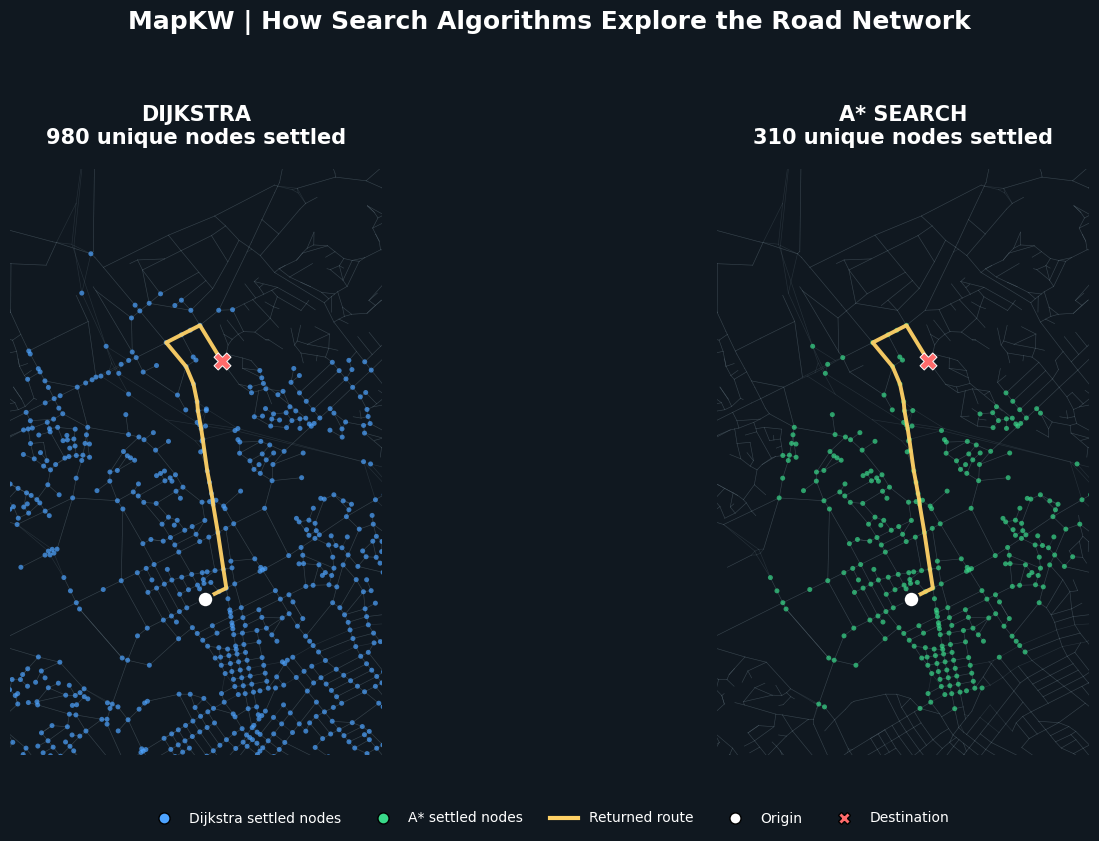

Dijkstra unique nodes settled: 980
A* unique nodes settled: 310
Reduction in settled nodes: 68.4%
Dijkstra estimated travel time: 274.92 sec
A* estimated travel time: 274.92 sec


In [81]:

# MapKW | Visualization B1: Dijkstra vs. A* Search Exploration
# Self-contained visualization; does not modify existing graph or functions.

import heapq
import math
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def mapkw_viz_trace_search(graph, source, target, algorithm="dijkstra"):
    """
    Trace settled nodes in Dijkstra or A* using travel_time weights.
    Supports MultiDiGraph parallel edges by selecting the minimum weight.
    Returns explored nodes and the final path.
    """
    def heuristic(node):
        if algorithm == "dijkstra":
            return 0.0

        x1, y1 = graph.nodes[node]["x"], graph.nodes[node]["y"]
        x2, y2 = graph.nodes[target]["x"], graph.nodes[target]["y"]
        return math.hypot(x2 - x1, y2 - y1) / 27.78

    frontier = [(heuristic(source), 0.0, source)]
    best_g = {source: 0.0}
    parents = {}
    settled = set()
    explored_order = []

    while frontier:
        f_score, g_score, node = heapq.heappop(frontier)

        # Ignore outdated queue entries and previously settled nodes.
        if node in settled or g_score > best_g[node] + 1e-9:
            continue

        settled.add(node)
        explored_order.append(node)

        if node == target:
            path = [target]
            while path[-1] != source:
                path.append(parents[path[-1]])
            path.reverse()
            return explored_order, path, g_score

        for neighbor, parallel_edges in graph[node].items():
            if neighbor in settled:
                continue

            edge_cost = min(
                data["travel_time"]
                for data in parallel_edges.values()
            )

            new_g = g_score + edge_cost

            if new_g < best_g.get(neighbor, float("inf")):
                best_g[neighbor] = new_g
                parents[neighbor] = node
                heapq.heappush(
                    frontier,
                    (new_g + heuristic(neighbor), new_g, neighbor)
                )

    raise ValueError("No route found between the selected nodes.")


# Use the same source and destination from the original experiment.
mapkw_viz_source = orig_node
mapkw_viz_target = dest_node

mapkw_viz_d_nodes, mapkw_viz_d_path, mapkw_viz_d_cost = (
    mapkw_viz_trace_search(
        G_weighted, mapkw_viz_source, mapkw_viz_target, "dijkstra"
    )
)

mapkw_viz_a_nodes, mapkw_viz_a_path, mapkw_viz_a_cost = (
    mapkw_viz_trace_search(
        G_weighted, mapkw_viz_source, mapkw_viz_target, "astar"
    )
)

# Build a consistent geographic viewing window for both panels.
mapkw_viz_path_x = [G_weighted.nodes[n]["x"] for n in mapkw_viz_d_path]
mapkw_viz_path_y = [G_weighted.nodes[n]["y"] for n in mapkw_viz_d_path]

mapkw_viz_padding = 1800  # metres

mapkw_viz_xlim = (
    min(mapkw_viz_path_x) - mapkw_viz_padding,
    max(mapkw_viz_path_x) + mapkw_viz_padding
)
mapkw_viz_ylim = (
    min(mapkw_viz_path_y) - mapkw_viz_padding,
    max(mapkw_viz_path_y) + mapkw_viz_padding
)

# Plot road network and exploration on identical map extents.
mapkw_viz_fig, mapkw_viz_axes = plt.subplots(
    1, 2, figsize=(16, 8), facecolor="#101820"
)

mapkw_viz_configs = [
    ("DIJKSTRA", mapkw_viz_d_nodes, mapkw_viz_d_path, "#4DA3FF"),
    ("A* SEARCH", mapkw_viz_a_nodes, mapkw_viz_a_path, "#39D98A")
]

for ax, (name, explored, path, color) in zip(
    mapkw_viz_axes, mapkw_viz_configs
):
    ax.set_facecolor("#101820")

    # Draw the road network as a subtle background.
    for u, v in G_weighted.edges():
        x1, y1 = G_weighted.nodes[u]["x"], G_weighted.nodes[u]["y"]
        x2, y2 = G_weighted.nodes[v]["x"], G_weighted.nodes[v]["y"]

        if (
            max(x1, x2) < mapkw_viz_xlim[0]
            or min(x1, x2) > mapkw_viz_xlim[1]
            or max(y1, y2) < mapkw_viz_ylim[0]
            or min(y1, y2) > mapkw_viz_ylim[1]
        ):
            continue

        ax.plot(
            [x1, x2], [y1, y2],
            color="#52616B", linewidth=0.45,
            alpha=0.32, zorder=1
        )

    # Highlight settled nodes.
    explored_x = [G_weighted.nodes[n]["x"] for n in explored]
    explored_y = [G_weighted.nodes[n]["y"] for n in explored]

    ax.scatter(
        explored_x, explored_y,
        s=13, c=color, alpha=0.7,
        edgecolors="none", zorder=3
    )

    # Highlight the returned route.
    route_x = [G_weighted.nodes[n]["x"] for n in path]
    route_y = [G_weighted.nodes[n]["y"] for n in path]

    ax.plot(
        route_x, route_y,
        color="#FFD166", linewidth=2.8,
        alpha=0.95, zorder=5
    )

    # Mark the origin and destination.
    ax.scatter(
        route_x[0], route_y[0],
        s=125, c="#FFFFFF", marker="o",
        edgecolors="#101820", linewidths=1.5, zorder=7
    )
    ax.scatter(
        route_x[-1], route_y[-1],
        s=150, c="#FF6B6B", marker="X",
        edgecolors="#FFFFFF", linewidths=0.7, zorder=7
    )

    ax.set_xlim(mapkw_viz_xlim)
    ax.set_ylim(mapkw_viz_ylim)
    ax.set_aspect("equal")
    ax.axis("off")

    ax.set_title(
        f"{name}\n{len(explored):,} unique nodes settled",
        color="white", fontsize=15,
        fontweight="bold", pad=18
    )

mapkw_viz_reduction = (
    1 - len(mapkw_viz_a_nodes) / len(mapkw_viz_d_nodes)
) * 100

mapkw_viz_fig.suptitle(
    "MapKW | How Search Algorithms Explore the Road Network",
    fontsize=18, fontweight="bold", color="white", y=1.02
)

mapkw_viz_legend = [
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor="#4DA3FF", markersize=8,
           label="Dijkstra settled nodes"),
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor="#39D98A", markersize=8,
           label="A* settled nodes"),
    Line2D([0], [0], color="#FFD166", linewidth=3,
           label="Returned route"),
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor="white", markersize=8,
           label="Origin"),
    Line2D([0], [0], marker="X", color="none",
           markerfacecolor="#FF6B6B", markersize=8,
           label="Destination")
]

mapkw_viz_fig.legend(
    handles=mapkw_viz_legend,
    loc="lower center", ncol=5,
    frameon=False, labelcolor="white",
    bbox_to_anchor=(0.5, -0.015)
)

plt.tight_layout(rect=[0, 0.07, 1, 0.97])
plt.show()

print(f"Dijkstra unique nodes settled: {len(mapkw_viz_d_nodes):,}")
print(f"A* unique nodes settled: {len(mapkw_viz_a_nodes):,}")
print(f"Reduction in settled nodes: {mapkw_viz_reduction:.1f}%")
print(f"Dijkstra estimated travel time: {mapkw_viz_d_cost:.2f} sec")
print(f"A* estimated travel time: {mapkw_viz_a_cost:.2f} sec")


### 2.5 Search Exploration Results

| Metric | Dijkstra | A* |
|---|---:|---:|
| Priority-queue removals | 1,255 | 398 |

For this route, A* performs approximately **68.3% fewer priority-queue removals** than the custom Dijkstra implementation.

This is a useful illustration of heuristic-guided search.

Dijkstra expands its search based on accumulated cost, while A* uses both accumulated cost and an estimate of the remaining distance to prioritize promising routes.

The result supports the idea that geographic information can substantially reduce search effort on a spatial network.

It does not mean that 68.3% of all graph nodes were eliminated, nor does it guarantee a corresponding reduction in runtime.

A broader benchmark would be needed to establish whether this improvement holds across short, long, central, and peripheral journeys.

## 2.6 Bidirectional Dijkstra and Breadth-First Search

To expand the comparison, I introduce two additional algorithms.

### Bidirectional Dijkstra

Standard Dijkstra searches outward from the origin.

Bidirectional Dijkstra performs two coordinated weighted searches: one forward from the origin and one backward from the destination.

The algorithm identifies a minimum-cost route by combining information from both search directions.

This approach can reduce the portion of the network explored before an optimal route is found.

For directed road networks, the backward search must account for edge direction rather than assuming every road is traversable both ways.

### Breadth-First Search (BFS)

BFS explores an unweighted graph level by level.

Its optimization objective is:

$$
P^*_{\text{BFS}}=\arg\min_{P\in\mathcal{P}(s,t)}|E(P)|
$$

In other words, BFS minimizes the number of edges traversed.

It does not account for road length or travel time when selecting a path.

With an adjacency-list representation, BFS has time complexity:

$$
O(|V|+|E|)
$$

### Why Include BFS?

BFS provides a useful structural baseline.

It helps demonstrate that minimizing the number of road-network segments is not equivalent to minimizing driving time.

After finding the BFS path, I evaluate its total travel-time cost using the same weighted graph used by the other algorithms.

This allows a direct comparison between a hop-minimizing route and travel-time-optimized routes.

In [63]:
# II. Bidirectional Dijkstra and BFS Baseline Implementation (Corrected)
import time
import networkx as nx

def run_bidirectional_dijkstra(G, source, target, weight='travel_time'):
    """Bidirectional Dijkstra Search running simultaneous forward and backward searches."""
    start_time = time.time()
    
    # NetworkX builtin weighted bidirectional Dijkstra returns (length, path)
    length, path = nx.bidirectional_dijkstra(G, source=source, target=target, weight=weight)
    
    exec_time = (time.time() - start_time) * 1000  # milliseconds
    return path, length, exec_time

def run_bfs(G, source, target):
    """Breadth-First Search (Unweighted structural baseline ignoring edge weights)."""
    start_time = time.time()
    
    # BFS finds the shortest path by hop count (ignoring travel time weights)
    path = nx.shortest_path(G, source=source, target=target)
    length = nx.path_weight(G, path, weight='travel_time')  # Evaluated against travel time cost
    
    exec_time = (time.time() - start_time) * 1000  # milliseconds
    return path, length, exec_time

print("Bidirectional Dijkstra and BFS baseline functions defined successfully!")

Bidirectional Dijkstra and BFS baseline functions defined successfully!


In [64]:
# Testing and Benchmarking Bidirectional Dijkstra & BFS from Laurier to Conestoga Mall
path_bi, time_bi, exec_bi = run_bidirectional_dijkstra(G_weighted, orig_node, dest_node)
path_bfs, time_bfs, exec_bfs = run_bfs(G_weighted, orig_node, dest_node)

print("Bidirectional Dijkstra:")
print(f"Path length (nodes): {len(path_bi)}")
print(f"Travel time (seconds): {time_bi:.2f}")
print(f"Execution time (milliseconds): {exec_bi:.4f}")

print("\nBreadth-First Search (BFS Baseline):")
print(f"Path length (nodes): {len(path_bfs)}")
print(f"Travel time (seconds): {time_bfs:.2f}")
print(f"Execution time (milliseconds): {exec_bfs:.4f}")

print(f"\nDo Bidirectional Dijkstra and Dijkstra match optimal travel time? {time_bi == time_d}")
print(f"BFS travel time penalty vs Optimal: {time_bfs - time_d:.2f} seconds slower")
print(f"Do both return identical optimal paths for Bidirectional? {path_bi == path_d}")

Bidirectional Dijkstra:
Path length (nodes): 21
Travel time (seconds): 274.92
Execution time (milliseconds): 1.6377

Breadth-First Search (BFS Baseline):
Path length (nodes): 18
Travel time (seconds): 301.88
Execution time (milliseconds): 0.6299

Do Bidirectional Dijkstra and Dijkstra match optimal travel time? True
BFS travel time penalty vs Optimal: 26.96 seconds slower
Do both return identical optimal paths for Bidirectional? True


### 2.7 Bidirectional Dijkstra and BFS Results

| Metric | Bidirectional Dijkstra | BFS |
|---|---:|---:|
| Path nodes | 21 | 18 |
| Estimated travel time | 274.92 sec | 301.88 sec |
| Execution time | 1.6377 ms | 0.6299 ms |

Bidirectional Dijkstra returns the same minimum estimated travel time as standard Dijkstra.

BFS produces a path with fewer nodes, but its estimated travel time is **26.96 seconds longer**, approximately a 9.8% increase over the optimal route.

This highlights an important distinction:

**The path with the fewest graph edges is not necessarily the fastest driving route.**

BFS is also faster in this individual test, but that comparison needs context: it is solving a different optimization problem.

The weighted algorithms minimize estimated travel time, whereas BFS minimizes hop count.

These results demonstrate why the choice of edge weights and optimization objective matters as much as the choice of algorithm.

# 3. Alternative Route Generation

## 3.1 Yen's K-Shortest Paths Algorithm

Finding the fastest route is useful, but a navigation system becomes more interesting when it can provide alternatives.

A driver might prefer a slightly longer journey because it follows a different road, avoids a particular area, or offers a simpler route.

To explore this, I use **Yen's K-shortest paths algorithm**, which identifies multiple loopless paths between the same origin and destination.

Unlike a standard shortest-path algorithm, which returns one optimal path, Yen's algorithm generates paths in ascending order of their total weight.

For the set of returned paths:

$$
T(P_1)\leq T(P_2)\leq \cdots\leq T(P_K)
$$

Where $P_1$ is the minimum-cost path and subsequent paths are increasingly expensive alternatives.

### How Yen's Algorithm Works

The algorithm begins by finding the shortest path between the origin and destination.

It then generates alternative candidates by temporarily deviating from portions of previously identified paths.

For each candidate:

- A **root path** preserves an initial portion of an existing route.
- A **spur node** identifies the point where an alternative route can branch.
- A **spur path** connects that node to the destination while respecting the algorithm's restrictions.

The algorithm evaluates candidate routes and selects the next lowest-cost loopless path until the requested number of routes has been generated.

### Implementation in MapKW

I use NetworkX's `shortest_simple_paths` functionality to generate four candidate routes:

- Route A: Optimal route
- Route B: First alternative
- Route C: Second alternative
- Route D: Third alternative

The implementation converts the original `MultiDiGraph` into a `DiGraph` for compatibility.

This conversion is a modelling compromise because the original graph can contain parallel edges with different attributes. The alternative-route results therefore require care when interpreting edge costs.

### An Important Limitation

The four shortest paths are not necessarily four meaningfully different driving routes.

Two paths may share almost all their road segments and differ only at one intersection.

Yen's algorithm guarantees an ordering of candidate paths under the graph and weights it receives. It does not independently optimize for geographic diversity, route simplicity, or driver preferences.

In [65]:
# Module 3.1: Yen's K-Shortest Paths Implementation (Multigraph-Compatible)
import time
import itertools
import networkx as nx

def run_yen_shortest_paths(G, source, target, k=4, weight='travel_time'):
    """
    Computes the top K shortest loopless paths between source and target 
    using Yen's algorithm by converting MultiDiGraph to DiGraph compatibility.
    """
    start_time = time.time()
    
    # If G is a MultiDiGraph, convert to DiGraph for shortest_simple_paths compatibility
    if isinstance(G, (nx.MultiGraph, nx.MultiDiGraph)):
        G_compat = nx.DiGraph(G)
    else:
        G_compat = G
        
    # nx.shortest_simple_paths yields paths in increasing order of weight
    path_generator = nx.shortest_simple_paths(G_compat, source=source, target=target, weight=weight)
    
    routes = []
    # Take the top k paths safely
    for path in itertools.islice(path_generator, k):
        length = nx.path_weight(G_compat, path, weight=weight)
        routes.append((path, length))
        
    exec_time = (time.time() - start_time) * 1000  # milliseconds
    return routes, exec_time

print("Yen's K-Shortest Paths function updated successfully!")

Yen's K-Shortest Paths function updated successfully!


In [66]:
# Test Yen's Algorithm from Laurier to Conestoga Mall (K = 4)
k_routes, yen_exec_time = run_yen_shortest_paths(G_weighted, orig_node, dest_node, k=4, weight='travel_time')

print(f"Yen's Algorithm generated {len(k_routes)} distinct routes in {yen_exec_time:.2f} ms:\n")

for i, (path, travel_time) in enumerate(k_routes):
    route_label = chr(65 + i)  # Converts 0->A, 1->B, 2->C, 3->D
    print(f"Route {route_label}:")
    print(f"  - Path length (nodes): {len(path)}")
    print(f"  - Travel time: {travel_time:.2f} seconds ({travel_time/60:.2f} minutes)")
    print(f"  - First 5 nodes: {path[:5]}...\n")

Yen's Algorithm generated 4 distinct routes in 163.03 ms:

Route A:
  - Path length (nodes): 21
  - Travel time: 274.92 seconds (4.58 minutes)
  - First 5 nodes: [3008, 322, 319, 320, 317]...

Route B:
  - Path length (nodes): 25
  - Travel time: 283.28 seconds (4.72 minutes)
  - First 5 nodes: [3008, 3009, 3011, 3006, 3004]...

Route C:
  - Path length (nodes): 22
  - Travel time: 285.02 seconds (4.75 minutes)
  - First 5 nodes: [3008, 322, 319, 320, 317]...

Route D:
  - Path length (nodes): 23
  - Travel time: 287.38 seconds (4.79 minutes)
  - First 5 nodes: [3008, 3009, 3011, 3006, 3007]...



## 3.2 Alternative Route Results

Yen's algorithm generates four candidate routes for the Laurier-to-Conestoga Mall example.

| Route | Path Nodes | Est. Travel Time | Additional Time |
|---|---:|---:|---:|
| A (Optimal) | 21 | 274.92 sec | — |
| B | 25 | 283.28 sec | +8.36 sec |
| C | 22 | 285.02 sec | +10.10 sec |
| D | 23 | 287.38 sec | +12.46 sec |

All four routes have estimated travel times within approximately 13 seconds of the fastest route.

This is an interesting result because it suggests that multiple near-optimal paths exist for this origin-destination pair.

However, the small travel-time differences also mean that the alternatives are relatively close in cost.

**What this tells me:** A single optimal route does not capture every potentially useful option. Alternative-route generation provides more flexibility, even when the differences in estimated travel time are small.

**What it does not tell me:** Whether the routes use substantially different streets, avoid congestion, or provide a better driving experience.

Those questions would require additional metrics such as shared-edge percentage, number of turns, or route overlap.

## 3.3 Evaluating Route Trade-offs

Travel time is the primary optimization objective, but I also want to compare the physical and structural characteristics of each candidate route.

I use Pandas to aggregate the following metrics.

### Total Route Distance

$$
D(P)=\frac{1}{1000}\sum_{e\in P}d_e
$$

Where $d_e$ is the length of each road segment in metres, giving the total distance in kilometres.

### Estimated Travel Time

$$
T_{\text{min}}(P)=\frac{1}{60}\sum_{e\in P}t_e
$$

### Travel-Time Penalty

$$
\Delta T(P_i)=T(P_i)-T(P_1)
$$

This measures how much additional estimated travel time an alternative requires relative to the fastest route.

### Node Count

$$
N(P)=|V(P)|
$$

This counts the number of graph nodes in a path.

I use node count as a simple structural descriptor. It is not a direct measure of driving complexity, since a route with more graph nodes does not necessarily require more turns or difficult manoeuvres.

Together, these metrics help distinguish routes that are fastest, shortest in distance, or structurally different.

In [67]:
# Module 3.2: Comparative Metrics Aggregator (Pandas Engine)
import pandas as pd

def generate_route_metrics(G, k_routes):
    """
    Computes comparative routing metrics (Distance in km, Travel Time in min/sec,
    and Node Turn Complexity) for a list of (path, travel_time) tuples.
    Returns a formatted Pandas DataFrame.
    """
    metrics_data = []
    
    # Baseline optimal time (Route A) for calculating relative time penalties
    optimal_time_sec = k_routes[0][1] if k_routes else 0
    
    for i, (path, travel_time_sec) in enumerate(k_routes):
        # Generate clean labels: Route A (Optimal), Route B (Alt 1), etc.
        letter = chr(65 + i)
        label = f"Route {letter} (Optimal)" if i == 0 else f"Route {letter} (Alt {i})"
        
        # Calculate total physical distance (meters -> kilometers)
        total_dist_meters = 0.0
        for u, v in zip(path[:-1], path[1:]):
            # In a MultiDiGraph, G[u][v] is a dictionary of parallel edges keyed by edge index (usually 0)
            edge_data = G[u][v][0]
            total_dist_meters += edge_data.get('length', 0.0)
            
        total_dist_km = total_dist_meters / 1000.0
        travel_time_min = travel_time_sec / 60.0
        time_penalty_sec = travel_time_sec - optimal_time_sec
        
        metrics_data.append({
            "Route": label,
            "Distance (km)": round(total_dist_km, 2),
            "Est. Time (min)": round(travel_time_min, 2),
            "Est. Time (sec)": round(travel_time_sec, 2),
            "Time Diff (+sec)": round(time_penalty_sec, 2),
            "Node Count (Complexity)": len(path)
        })
        
    df_metrics = pd.DataFrame(metrics_data)
    return df_metrics

print("Comparative Metrics Aggregator function defined successfully!")

Comparative Metrics Aggregator function defined successfully!


In [68]:
# Generate and display the Comparative Metrics Table for Laurier -> Conestoga Mall
df_route_comparison = generate_route_metrics(G_weighted, k_routes)

print("--- Comparative Route Metrics (Laurier to Conestoga Mall) ---")
display(df_route_comparison)

--- Comparative Route Metrics (Laurier to Conestoga Mall) ---


,Route,Distance (km),Est. Time (min),Est. Time (sec),Time Diff (+sec),Node Count (Complexity)
0,Route A (Optimal),4.23,4.58,274.92,0.00,21
1,Route B (Alt 1),4.35,4.72,283.28,8.36,25
2,Route C (Alt 2),4.15,4.75,285.02,10.10,22
3,Route D (Alt 3),4.35,4.79,287.38,12.46,23


## 3.4 Comparative Route Analysis

The route comparison table reveals a useful distinction between distance and travel time.

**Route A** has the lowest estimated travel time at 4.58 minutes and a reported distance of 4.23 km.

**Route C** has the shortest reported distance at 4.15 km, but takes approximately 10.10 seconds longer than Route A.

This illustrates a central concept in weighted graph optimization:

> The shortest route by distance is not necessarily the fastest route by estimated travel time.

The result is consistent with a model in which roads have different estimated speeds.

Route B has the highest node count at 25, while Route A uses 21 nodes. However, I would not interpret this difference as evidence of additional turns without explicitly calculating turning angles or manoeuvres.

One technical consideration is that the current distance aggregation selects the parallel edge with key `0`, while the pathfinding functions may evaluate parallel edges differently. As a result, the distance and time metrics should be treated as preliminary until edge selection is validated.

For now, this comparison demonstrates how a routing system can expose trade-offs between multiple metrics rather than presenting only one recommended journey.

# 4. Interactive Route Exploration

## 4.1 Connecting Geographic Locations to Graph Search

So far, the algorithms have operated on node IDs.

That works for experimentation, but a user-facing routing tool should allow someone to select recognizable locations instead.

To bridge this gap, I create a dictionary of eight landmarks across Kitchener-Waterloo, each associated with geographic coordinates.

I then use `ipywidgets` to build origin and destination dropdown selectors.

### Why Spatial Snapping Is Necessary

The user selects a landmark, but the graph search requires a valid source and destination node.

The workflow is:

1. Select the origin and destination landmarks.
2. Retrieve their latitude and longitude.
3. Transform those coordinates into the graph's projected CRS.
4. Snap each location to its nearest graph node.
5. Run the routing algorithm using the selected nodes.

This separates the user-facing location representation from the underlying graph structure.

The initial widget implementation provides the location-selection interface. The subsequent cells connect the routing results to an interactive map.

In [69]:
# Module 4.1: Spatial Coordinate Snapping & ipywidgets UI
import ipywidgets as widgets
from IPython.display import display, clear_output

# 1. Define the 8 Iconic Waterloo-Kitchener Landmarks (Lat, Lon)
WATERLOO_LANDMARKS = {
    "Wilfrid Laurier University": (43.4743, -80.5280),
    "Conestoga Mall": (43.4934, -80.5055),
    "University of Waterloo": (43.4723, -80.5449),
    "Uptown Waterloo": (43.4653, -80.5224),
    "Kitchener City Hall": (43.4504, -80.4832),
    "Fairway Station": (43.4312, -80.4498),
    "Kitchener GO": (43.4517, -80.4891),
    "RIM Park": (43.5132, -80.5135)
}

# 2. Re-verify the spatial projection snapping helper function
def get_node_in_projected_graph(G, lat, lon):
    """Projects a lat/lon point to match the graph's UTM CRS and finds the nearest node."""
    pt = gpd.GeoDataFrame(geometry=[Point(lon, lat)], crs="EPSG:4326")
    pt_proj = pt.to_crs(G.graph['crs'])
    x_proj, y_proj = pt_proj.geometry.x.iloc[0], pt_proj.geometry.y.iloc[0]
    return ox.distance.nearest_nodes(G, X=x_proj, Y=y_proj)

# 3. Create interactive ipywidgets dropdown selectors
origin_dropdown = widgets.Dropdown(
    options=list(WATERLOO_LANDMARKS.keys()),
    value="Wilfrid Laurier University",
    description="Origin:",
    style={'description_width': 'initial'}
)

dest_dropdown = widgets.Dropdown(
    options=list(WATERLOO_LANDMARKS.keys()),
    value="Conestoga Mall",
    description="Destination:",
    style={'description_width': 'initial'}
)

# Output display area for debugging / widget state
output_widget = widgets.Output()

def on_selection_change(change):
    with output_widget:
        clear_output(wait=True)
        orig_name = origin_dropdown.value
        dest_name = dest_dropdown.value
        print(f"Selected Route: {orig_name} ➔ {dest_name}")

origin_dropdown.observe(on_selection_change, names='value')
dest_dropdown.observe(on_selection_change, names='value')

# Display the widget controls
print("Select Origin and Destination Landmarks:")
display(origin_dropdown, dest_dropdown, output_widget)

Select Origin and Destination Landmarks:


Dropdown(description='Origin:', options=('Wilfrid Laurier University', 'Conestoga Mall', 'University of Waterl…

Dropdown(description='Destination:', index=1, options=('Wilfrid Laurier University', 'Conestoga Mall', 'Univer…

Output()

## 4.2 Visualizing Routes with Folium

A numerical route comparison is useful, but it cannot show how routes relate geographically.

I use Folium to build an interactive map with Esri street-map tiles.

The map is designed to distinguish:

- The selected origin and destination
- The minimum estimated travel-time route
- Three alternative routes
- Route-specific distance, travel-time, and node-count information

The optimal route is displayed in blue, while the alternatives use orange.

The visualization also exports a standalone HTML file, allowing the map to be opened outside the notebook.

### Coordinate System Considerations

An important detail is that the routing graph uses projected coordinates in metres, whereas Folium expects geographic coordinates in latitude-longitude format.

The current visualization functions pass graph-node `x` and `y` values directly into Folium. Because these values are projected coordinates, the resulting route polylines are not yet reliably represented in the map's expected coordinate system.

This is a visualization limitation rather than a shortest-path algorithm limitation.

The later Tableau export pipeline addresses this by explicitly converting projected node coordinates back into EPSG:4326 geographic coordinates.

The prototype therefore establishes the intended visualization workflow, while the final geographic data pipeline provides a more suitable basis for accurate mapping.

In [70]:
# Module 4.2: Bulletproof Key-Free Esri Street Map Dashboard
import folium

def visualize_routes_on_map(G, k_routes, df_metrics, orig_coords, dest_coords):
    center_lat = (orig_coords[0] + dest_coords[0]) / 2
    center_lon = (orig_coords[1] + dest_coords[1]) / 2
    
    # Initialize Folium Map with Esri World Street Map (Zero API keys, 100% free public tiles)
    m = folium.Map(
        location=[center_lat, center_lon], 
        zoom_start=13, 
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
        attr="Tiles &copy; Esri &mdash; Source: Esri, DeLorme, NAVTEQ, USGS, Intermap, iPC, NRCAN, and the GIS User Community"
    )
    
    # Add Origin and Destination Markers
    folium.Marker(
        location=orig_coords,
        popup="<b>Origin:</b> Wilfrid Laurier University",
        icon=folium.Icon(color="green", icon="play")
    ).add_to(m)
    
    folium.Marker(
        location=dest_coords,
        popup="<b>Destination:</b> Conestoga Mall",
        icon=folium.Icon(color="red", icon="stop")
    ).add_to(m)
    
    # Define styling: Route A gets primary Electric Blue, Alternatives get Soft Orange
    colors = ["#0066ff", "#ff7800", "#ff7800", "#ff7800"]
    weights = [6, 4, 4, 4]
    opacities = [0.9, 0.6, 0.6, 0.6]
    
    for i, (path, travel_time_sec) in enumerate(k_routes):
        letter = chr(65 + i)
        route_row = df_metrics.iloc[i]
        
        latlon_path = []
        for node in path:
            lat = G.nodes[node]['y']
            lon = G.nodes[node]['x']
            latlon_path.append((lat, lon))
            
        popup_html = f"""
        <div style="font-family: Arial; font-size: 12px; width: 160px;">
            <b>Route {letter}</b><br>
            Distance: {route_row['Distance (km)']} km<br>
            Time: {route_row['Est. Time (min)']} min<br>
            Nodes: {route_row['Node Count (Complexity)']}
        </div>
        """
        
        folium.PolyLine(
            locations=latlon_path,
            color=colors[i],
            weight=weights[i],
            opacity=opacities[i],
            popup=folium.Popup(popup_html, max_width=200),
            tooltip=f"Click for Route {letter} Details"
        ).add_to(m)
        
    # Save standalone HTML export
    output_filename = "waterloo_routes_demo.html"
    m.save(output_filename)
    print(f"Interactive dashboard successfully exported to '{output_filename}' using Esri Street Map tiles!")
    
    return m

# Run and display
route_map = visualize_routes_on_map(G_weighted, k_routes, df_route_comparison, orig_coords, dest_coords)
display(route_map)

Interactive dashboard successfully exported to 'waterloo_routes_demo.html' using Esri Street Map tiles!


## 4.3 Combining Route Selection, Computation, and Visualization

The next step brings the individual components into a single interactive notebook workflow.

The unified prototype connects:

- Landmark dropdown selectors
- Geographic coordinate lookup
- Nearest-node snapping
- Yen's K-shortest paths
- Route metric aggregation
- Folium map rendering

When the user selects an origin and destination, the notebook attempts to generate four candidate routes, calculate their metrics, and display the results.

This is an important step in moving from isolated algorithm experiments toward an end-to-end application.

It also introduces application-level considerations, including input validation, function return types, and consistent coordinate handling.

The prototype is an exploratory interface rather than a finished navigation application. Its role is to demonstrate how graph algorithms can support an interactive routing experience.

For the final Tableau dashboard, I use a different architecture: precomputing routes in Python and allowing Tableau to visualize the resulting dataset.

In [71]:
# Final Unified Dashboard: ipywidgets + NetworkX + Yen's Routing + Esri Map
import ipywidgets as widgets
from IPython.display import display, clear_output
import folium
import pandas as pd

# 1. Precise landmark coordinates for Waterloo Region
WATERLOO_LANDMARKS = {
    "Wilfrid Laurier University": (43.4743, -80.5280),
    "Conestoga Mall": (43.5140, -80.5085),  # Refined exact mall coordinate center
    "University of Waterloo": (43.4723, -80.5449),
    "Uptown Waterloo": (43.4653, -80.5224),
    "Kitchener City Hall": (43.4504, -80.4832),
    "Fairway Station": (43.4312, -80.4498),
    "Kitchener GO": (43.4517, -80.4891),
    "RIM Park": (43.5132, -80.5135)
}

# 2. Setup Widget Controls
origin_widget = widgets.Dropdown(
    options=list(WATERLOO_LANDMARKS.keys()),
    value="Wilfrid Laurier University",
    description="Origin:"
)

dest_widget = widgets.Dropdown(
    options=list(WATERLOO_LANDMARKS.keys()),
    value="Conestoga Mall",
    description="Destination:"
)

output_display = widgets.Output()

def run_dashboard(origin_name, dest_name):
    with output_display:
        clear_output(wait=True)
        
        if origin_name == dest_name:
            print("⚠️ Origin and Destination must be different!")
            return
            
        # Get coordinates
        orig_lat, orig_lon = WATERLOO_LANDMARKS[origin_name]
        dest_lat, dest_lon = WATERLOO_LANDMARKS[dest_name]
        
        # Snapping to nodes
        orig_node = get_node_in_projected_graph(G_weighted, orig_lat, orig_lon)
        dest_node = get_node_in_projected_graph(G_weighted, dest_lat, dest_lon)
        
        # Compute Yen's K-Shortest Paths (K=4)
        k_routes = run_yen_shortest_paths(G_weighted, orig_node, dest_node, k=4)
        
        if not k_routes:
            print("❌ No route found between these landmarks.")
            return
            
        # Generate Metrics DataFrame
        df_metrics = generate_route_metrics(G_weighted, k_routes)
        print(f"--- Routing Results: {origin_name} ➔ {dest_name} ---")
        display(df_metrics)
        
        # Build Esri Map
        center_lat = (orig_lat + dest_lat) / 2
        center_lon = (orig_lon + dest_lon) / 2
        m = folium.Map(
            location=[center_lat, center_lon], 
            zoom_start=13, 
            tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
            attr="Tiles &copy; Esri"
        )
        
        folium.Marker(location=(orig_lat, orig_lon), popup=f"<b>Origin:</b> {origin_name}", icon=folium.Icon(color="green", icon="play")).add_to(m)
        folium.Marker(location=(dest_lat, dest_lon), popup=f"<b>Destination:</b> {dest_name}", icon=folium.Icon(color="red", icon="stop")).add_to(m)
        
        colors = ["#0066ff", "#ff7800", "#ff7800", "#ff7800"]
        weights = [6, 4, 4, 4]
        opacities = [0.9, 0.6, 0.6, 0.6]
        
        for i, (path, _) in enumerate(k_routes):
            letter = chr(65 + i)
            latlon_path = [(G_weighted.nodes[n]['y'], G_weighted.nodes[n]['x']) for n in path]
            
            popup_html = f"<b>Route {letter}</b><br>Distance: {df_metrics.iloc[i]['Distance (km)']} km<br>Time: {df_metrics.iloc[i]['Est. Time (min)']} min"
            folium.PolyLine(locations=latlon_path, color=colors[i], weight=weights[i], opacity=opacities[i], popup=folium.Popup(popup_html, max_width=200)).add_to(m)
            
        display(m)

# Bind widgets to interactive runner
interactive_plot = widgets.interactive(run_dashboard, origin_name=origin_widget, dest_name=dest_widget)
display(interactive_plot)

interactive(children=(Dropdown(description='Origin:', options=('Wilfrid Laurier University', 'Conestoga Mall',…

# 5. Algorithm Performance Benchmarking

## 5.1 Comparing Search Strategies

The initial experiments compare algorithms individually. I now bring them into a common benchmarking function to evaluate their results using a consistent origin-destination pair.

The benchmark compares four algorithms:

| Algorithm | Search Strategy | Optimization Objective |
|---|---|---|
| Dijkstra | Cost-based search | Minimum estimated travel time |
| A* | Heuristic-guided search | Minimum estimated travel time, subject to heuristic conditions |
| Bidirectional Dijkstra | Forward and backward cost-based search | Minimum estimated travel time |
| BFS | Unweighted level-order search | Minimum edge count |

### Evaluation Metrics

**Execution time (ms):** The elapsed time required to compute a path.

**Estimated travel time (sec):** The sum of travel-time weights along the returned path.

**Path nodes:** The number of nodes in the returned path.

**Optimality:** Whether the algorithm returns a minimum travel-time path under the weighted graph model.

### Benchmarking Considerations

For a rigorous performance comparison, it is important to distinguish computational efficiency from route quality.

An algorithm can execute quickly but return a route with a higher travel-time cost. Conversely, a slower algorithm may provide a provably optimal result.

The current benchmark uses one execution per algorithm and one origin-destination pair. It is therefore an initial diagnostic rather than a statistically robust performance study.

A more complete benchmark would include repeated runs, multiple route lengths, timing distributions, and checks that weighted algorithms return equivalent minimum costs.

In [72]:
# Module 5.1: Unified Algorithm Performance Benchmark Engine
import time
import networkx as nx
import heapq

def benchmark_all_algorithms(G, source, target, weight='travel_time'):
    """
    Runs Dijkstra, A*, Bidirectional Dijkstra, and BFS on a given O-D pair,
    collecting execution time, nodes explored, path length, and travel time.
    """
    results = []
    
    # 1. Standard Dijkstra (using NetworkX)
    start = time.time()
    path_d = nx.shortest_path(G, source=source, target=target, weight=weight)
    time_d = nx.path_weight(G, path_d, weight=weight)
    exec_d = (time.time() - start) * 1000
    
    results.append({
        "Algorithm": "Dijkstra (Standard)",
        "Exec Time (ms)": round(exec_d, 3),
        "Travel Time (sec)": round(time_d, 2),
        "Path Nodes": len(path_d),
        "Optimality": "Optimal"
    })
    
    # 2. A* Search (using networkx with UTM Euclidean heuristic)
    def heuristic(u, v):
        x1, y1 = G.nodes[u]['x'], G.nodes[u]['y']
        x2, y2 = G.nodes[v]['x'], G.nodes[v]['y']
        return ((x2 - x1)**2 + (y2 - y1)**2)**0.5 / 27.78 # 100 km/h max speed cap
        
    start = time.time()
    path_a = nx.astar_path(G, source=source, target=target, heuristic=heuristic, weight=weight)
    time_a = nx.path_weight(G, path_a, weight=weight)
    exec_a = (time.time() - start) * 1000
    
    results.append({
        "Algorithm": "A* Search",
        "Exec Time (ms)": round(exec_a, 3),
        "Travel Time (sec)": round(time_a, 2),
        "Path Nodes": len(path_a),
        "Optimality": "Optimal (Pruned)"
    })
    
    # 3. Bidirectional Dijkstra
    start = time.time()
    time_bi, path_bi = nx.bidirectional_dijkstra(G, source=source, target=target, weight=weight)
    exec_bi = (time.time() - start) * 1000
    
    results.append({
        "Algorithm": "Bidirectional Dijkstra",
        "Exec Time (ms)": round(exec_bi, 3),
        "Travel Time (sec)": round(time_bi, 2),
        "Path Nodes": len(path_bi),
        "Optimality": "Optimal"
    })
    
    # 4. Breadth-First Search (BFS - Unweighted baseline)
    start = time.time()
    path_bfs = nx.shortest_path(G, source=source, target=target) # unweighted hop count
    time_bfs = nx.path_weight(G, path_bfs, weight=weight)
    exec_bfs = (time.time() - start) * 1000
    
    results.append({
        "Algorithm": "BFS (Unweighted Baseline)",
        "Exec Time (ms)": round(exec_bfs, 3),
        "Travel Time (sec)": round(time_bfs, 2),
        "Path Nodes": len(path_bfs),
        "Optimality": f"+{round(time_bfs - time_d, 2)}s Penalty"
    })
    
    return pd.DataFrame(results)

# Test the Benchmark Engine on Laurier -> Conestoga Mall
df_benchmark = benchmark_all_algorithms(G_weighted, orig_node, dest_node)
print("--- Algorithm Performance Benchmark ---")
display(df_benchmark)

--- Algorithm Performance Benchmark ---


,Algorithm,Exec Time (ms),Travel Time (sec),Path Nodes,Optimality
0,Dijkstra (Standard),2.026,274.92,21,Optimal
1,A* Search,2.214,274.92,21,Optimal (Pruned)
2,Bidirectional Dijkstra,1.035,274.92,21,Optimal
3,BFS (Unweighted Baseline),0.203,301.88,18,+26.96s Penalty


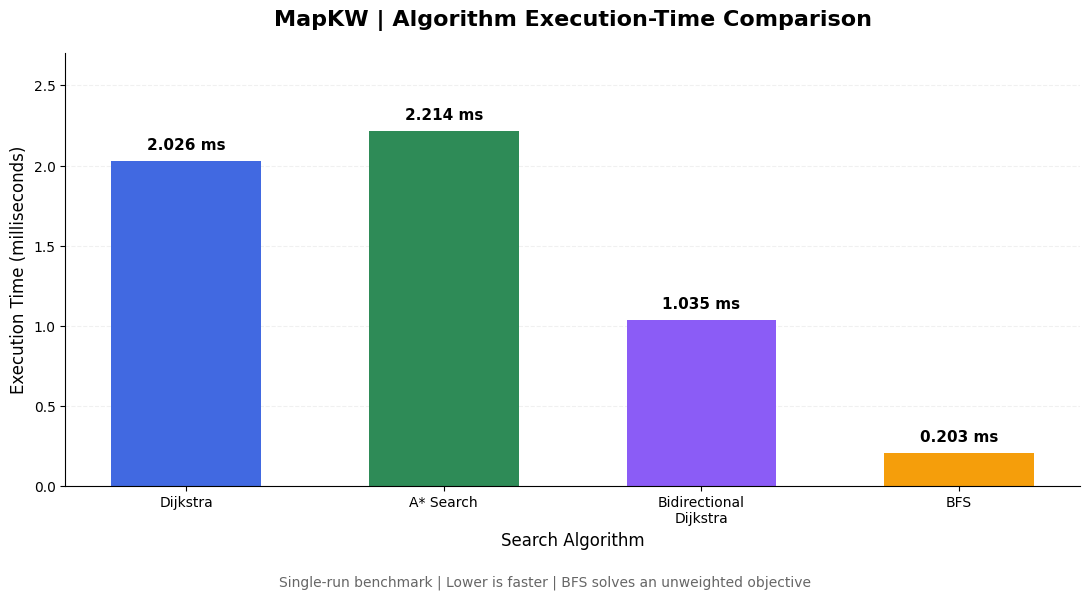

In [82]:

# MapKW | Visualization C1: Algorithm Execution-Time Comparison
# Uses existing df_benchmark. Does not modify benchmark results.

import matplotlib.pyplot as plt
import numpy as np

mapkw_viz_bench = df_benchmark.copy()

mapkw_viz_labels = [
    "Dijkstra",
    "A* Search",
    "Bidirectional\nDijkstra",
    "BFS"
]

mapkw_viz_runtime = mapkw_viz_bench["Exec Time (ms)"].to_numpy()

mapkw_viz_colors = [
    "#4169E1",
    "#2E8B57",
    "#8B5CF6",
    "#F59E0B"
]

mapkw_viz_fig, mapkw_viz_ax = plt.subplots(figsize=(11, 6))

mapkw_viz_bars = mapkw_viz_ax.bar(
    mapkw_viz_labels,
    mapkw_viz_runtime,
    color=mapkw_viz_colors,
    width=0.58,
    edgecolor="none"
)

for bar, value in zip(mapkw_viz_bars, mapkw_viz_runtime):
    mapkw_viz_ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(mapkw_viz_runtime) * 0.025,
        f"{value:.3f} ms",
        ha="center", va="bottom",
        fontsize=11, fontweight="bold"
    )

mapkw_viz_ax.set_title(
    "MapKW | Algorithm Execution-Time Comparison",
    fontsize=16, fontweight="bold", pad=20
)
mapkw_viz_ax.set_ylabel("Execution Time (milliseconds)", fontsize=12)
mapkw_viz_ax.set_xlabel("Search Algorithm", fontsize=12)

mapkw_viz_ax.set_ylim(0, max(mapkw_viz_runtime) * 1.22)
mapkw_viz_ax.grid(axis="y", alpha=0.18, linestyle="--")
mapkw_viz_ax.set_axisbelow(True)

mapkw_viz_ax.spines["top"].set_visible(False)
mapkw_viz_ax.spines["right"].set_visible(False)

mapkw_viz_fig.text(
    0.5, 0.015,
    "Single-run benchmark | Lower is faster | BFS solves an unweighted objective",
    ha="center", fontsize=10, color="#666666"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()


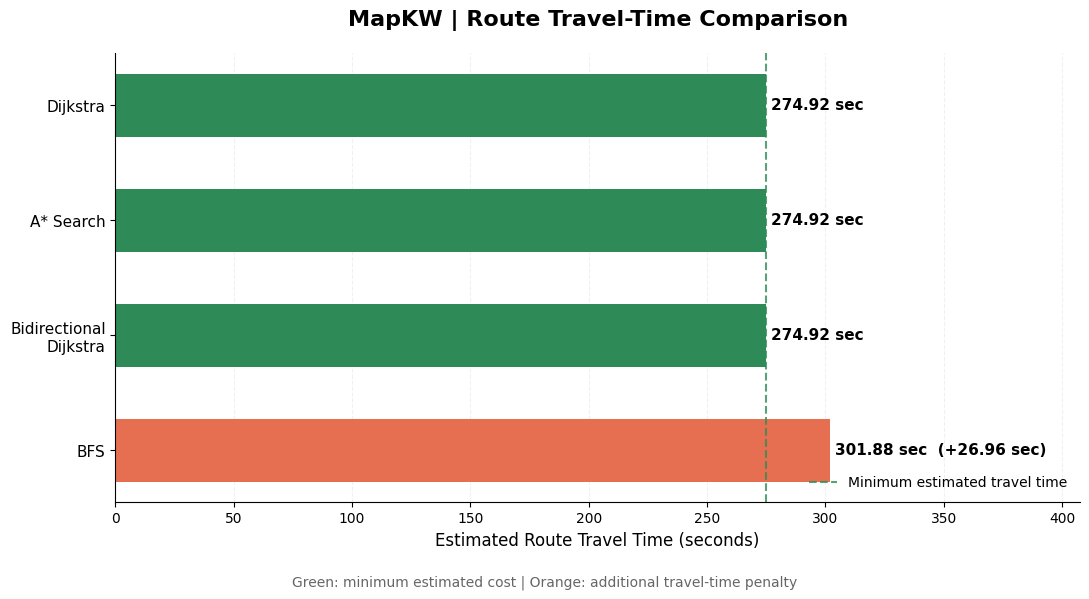

In [83]:

# MapKW | Visualization C2: Route Travel-Time Comparison
# Uses existing df_benchmark. No graph calculations are rerun.

import matplotlib.pyplot as plt
import numpy as np

mapkw_viz_travel = df_benchmark["Travel Time (sec)"].to_numpy()

mapkw_viz_best_time = min(mapkw_viz_travel)
mapkw_viz_penalties = mapkw_viz_travel - mapkw_viz_best_time

mapkw_viz_labels = [
    "Dijkstra",
    "A* Search",
    "Bidirectional\nDijkstra",
    "BFS"
]

mapkw_viz_colors = [
    "#2E8B57" if abs(penalty) < 1e-6 else "#E76F51"
    for penalty in mapkw_viz_penalties
]

mapkw_viz_fig, mapkw_viz_ax = plt.subplots(figsize=(11, 6))

mapkw_viz_y = np.arange(len(mapkw_viz_labels))

mapkw_viz_bars = mapkw_viz_ax.barh(
    mapkw_viz_y,
    mapkw_viz_travel,
    color=mapkw_viz_colors,
    height=0.55
)

mapkw_viz_ax.set_yticks(mapkw_viz_y)
mapkw_viz_ax.set_yticklabels(mapkw_viz_labels, fontsize=11)
mapkw_viz_ax.invert_yaxis()

for i, (time_sec, penalty) in enumerate(
    zip(mapkw_viz_travel, mapkw_viz_penalties)
):
    label = f"{time_sec:.2f} sec"

    if penalty > 1e-6:
        label += f"  (+{penalty:.2f} sec)"

    mapkw_viz_ax.text(
        time_sec + 2,
        i,
        label,
        va="center", ha="left",
        fontsize=11, fontweight="bold"
    )

mapkw_viz_ax.axvline(
    mapkw_viz_best_time,
    color="#2E8B57",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label="Minimum estimated travel time"
)

mapkw_viz_ax.set_title(
    "MapKW | Route Travel-Time Comparison",
    fontsize=16, fontweight="bold", pad=20
)

mapkw_viz_ax.set_xlabel(
    "Estimated Route Travel Time (seconds)",
    fontsize=12
)

mapkw_viz_ax.set_xlim(0, max(mapkw_viz_travel) * 1.35)
mapkw_viz_ax.grid(axis="x", alpha=0.18, linestyle="--")
mapkw_viz_ax.set_axisbelow(True)

mapkw_viz_ax.spines["top"].set_visible(False)
mapkw_viz_ax.spines["right"].set_visible(False)

mapkw_viz_ax.legend(
    loc="lower right",
    frameon=False,
    fontsize=10
)

mapkw_viz_fig.text(
    0.5, 0.015,
    "Green: minimum estimated cost | Orange: additional travel-time penalty",
    ha="center", fontsize=10, color="#666666"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()


## 5.2 Benchmark Results

| Algorithm | Execution Time | Est. Travel Time | Path Nodes |
|---|---:|---:|---:|
| Dijkstra | 2.026 ms | 274.92 sec | 21 |
| A* | 2.214 ms | 274.92 sec | 21 |
| Bidirectional Dijkstra | 1.035 ms | 274.92 sec | 21 |
| BFS | 0.203 ms | 301.88 sec | 18 |

### Observation 1: The Weighted Algorithms Agree

Dijkstra, A*, and Bidirectional Dijkstra all return the same estimated travel-time cost of 274.92 seconds.

This provides an initial consistency check for the weighted routing methods on the selected journey.

### Observation 2: Bidirectional Dijkstra Is Fastest Among the Weighted Algorithms

Bidirectional Dijkstra records the lowest execution time among the three weighted algorithms in this benchmark.

Its execution time is approximately 49% lower than standard Dijkstra's in this run.

This is consistent with the potential advantage of searching from both endpoints, but one measurement is not sufficient to establish a general performance ranking.

### Observation 3: A* Is Not Always Faster

Interestingly, A* takes slightly longer than standard Dijkstra in this benchmark, despite outperforming it in the earlier single-route test.

This is a useful reminder that reducing search effort does not automatically reduce execution time.

Heuristic calculations introduce additional computational overhead, and the performance benefit depends on the problem.

### Observation 4: BFS Is Fastest but Does Not Optimize Travel Time

BFS records the lowest execution time overall, but its route takes 26.96 seconds longer.

This is not a failure of BFS. It is performing the task it was designed for: minimizing the number of edges, rather than the weighted travel-time cost.

### Interpretation

The results show that there is no universally best algorithm independent of the optimization objective and evaluation criteria.

For this particular route, the weighted algorithms agree on the minimum estimated travel time, while BFS demonstrates the consequences of optimizing a different metric.

A broader set of experiments would be needed to determine which weighted algorithm performs most consistently across the region.

# 6. Expanding to Regional Origin-Destination Pairs

## 6.1 Building a Landmark Dataset

The initial experiments focus on one journey. To make MapKW useful for a regional dashboard, I expand the location dataset to 47 landmarks across Kitchener-Waterloo.

The landmark collection includes:

- Universities and campuses
- Urban centres
- Shopping destinations
- Grocery stores
- Parks and entertainment venues
- Sports and recreation facilities
- Transit hubs
- Community centres and libraries

I chose these categories to represent a range of everyday journeys rather than focusing exclusively on major intersections or city centres.

Each landmark is associated with a latitude-longitude coordinate and can be snapped to the road network.

### Why Use a Fixed Landmark Set?

The final dashboard is designed for Tableau Public, where precomputed routes provide a practical alternative to running graph algorithms on demand.

Using a defined landmark set allows me to calculate the routing combinations in Python and export the results as a structured dataset.

### Ordered Origin-Destination Pairs

For $n$ landmarks, the number of ordered origin-destination pairs excluding self-pairs is:

$$
N=n(n-1)
$$

With 47 landmarks:

$$
N=47(46)=2,162
$$

The pairs are ordered because travelling from A to B is not necessarily equivalent to travelling from B to A.

One-way streets and directional restrictions can produce different routes and travel costs in each direction.

With up to four candidate routes per pair, the pipeline can attempt to generate:

$$
2,162\times4=8,648
$$

candidate routes.

This provides the basis for the regional Tableau export.

In [ ]:
# Module 6.1: Corrected & Verified 47-Landmark Student Dictionary (Conestoga Mall Fixed)
KW_STUDENT_LANDMARKS = {
    # --- 1. Universities & Campuses ---
    "Wilfrid Laurier University": (43.4743, -80.5280),
    "University of Waterloo": (43.4723, -80.5449),
    "Conestoga College - Waterloo": (43.4862, -80.5285),
    "Conestoga College - Doon Campus": (43.3914, -80.4075),
    "Laurier Concourse": (43.4728, -80.5291),
    "UWaterloo Student Life Centre (SLC)": (43.4718, -80.5442),

    # --- 2. Key Urban Nodes ---
    "Uptown Waterloo": (43.4653, -80.5224),
    "Kitchener City Hall": (43.4504, -80.4832),

    # --- 3. Shopping & Malls ---
    "Conestoga Mall": (43.4978, -80.5263),  # Corrected to 550 King St N (True Mall Center)
    "Boardwalk KW": (43.4385, -80.5621),
    "Sunrise Shopping Centre": (43.4248, -80.4952),
    "Fairview Park Mall": (43.4285, -80.4492),
    "Kitchener Market": (43.4481, -80.4865),
    "St. Jacobs Market": (43.5385, -80.5572),

    # --- 4. Grocery Stores ---
    "T&T Supermarket Waterloo": (43.4731, -80.5372),
    "Boardwalk Walmart Supercentre": (43.4392, -80.5615),
    "Zehrs Columbia": (43.4765, -80.5501),
    "Sobeys Bridgeport": (43.4721, -80.5120),
    "Costco Wholesale Waterloo": (43.5082, -80.5421),
    "Kitchener Costco": (43.4312, -80.4712),

    # --- 5. Recreation, Parks & Entertainment ---
    "RIM Park": (43.5132, -80.5135),
    "Waterloo Park": (43.4672, -80.5312),
    "Victoria Park Kitchener": (43.4445, -80.4932),
    "Bechtel Park": (43.4835, -80.5012),
    "Galaxy Cinemas Waterloo": (43.4882, -80.5252),
    "Princess Cinemas Uptown": (43.4631, -80.5235),
    "Cineplex Cinemas Kitchener": (43.4352, -80.4592),
    "Auditoria (Kitchener Memorial)": (43.4582, -80.4721),
    "TheMuseum Kitchener": (43.4501, -80.4842),
    "Center in the Square": (43.4491, -80.4862),

    # --- 6. Sports Complexes & Indoor Courts ---
    "Waterloo Memorial Recreation Complex (Indoor Basketball/Pool)": (43.4642, -80.5185),
    "Manulife Financial Sportsplex (RIM Park Indoor Soccer)": (43.5132, -80.5135),
    "Activa Sportsplex (Indoor Ice/Courts)": (43.4095, -80.4782),
    "Albanese Park Indoor Basketball Courts": (43.4315, -80.4652),
    "Jimmy Thomson Pool & Community Centre": (43.4421, -80.4785),
    "Stork Family YMCA (Indoor Basketball & Courts)": (43.4281, -80.5152),

    # --- 7. Transit Hubs ---
    "Fairway Station": (43.4312, -80.4498),
    "Kitchener GO": (43.4517, -80.4891),
    "Central Station (Kitchener)": (43.4515, -80.4882),
    "Waterloo Public Square": (43.4651, -80.5228),
    "Laurier-Waterloo Park LRT": (43.4715, -80.5292),
    "UWaterloo LRT Station": (43.4705, -80.5412),

    # --- 8. Community Centres & Libraries ---
    "Kitchener Public Library Central": (43.4512, -80.4885),
    "Waterloo Public Library Main": (43.4642, -80.5205),
    "Breithaupt Centre": (43.4592, -80.4952),
    "Parkinson Community Centre": (43.4752, -80.5052)
}

# 7. Preparing the Tableau Routing Dataset

## 7.1 Transforming Projected Coordinates Back to GPS

The routing algorithms operate on a projected graph because metric coordinates are more appropriate for geometric calculations.

However, geographic visualization tools such as Tableau require coordinates in a geographic reference system.

To support this, I use `pyproj` to transform node coordinates from the graph's projected CRS into WGS84 (EPSG:4326).

Conceptually:

$$
(x_{\text{projected}},y_{\text{projected}})
\longrightarrow
(\text{longitude},\text{latitude})
$$

The transformation is configured with `always_xy=True` to maintain a consistent longitude-latitude axis order.

### Coordinate Validation

Before applying the transformation across the entire graph, I test it on a known route node.

The transformed result is:

- Latitude: 43.475057
- Longitude: -80.528028

The notebook verifies that the transformed point falls within broad geographic bounds around Kitchener-Waterloo.

This is a useful sanity check for detecting major coordinate-system errors.

It does not independently establish metre-level geographic accuracy, but it confirms that the transformation produces plausible regional GPS coordinates.

The same transformation is subsequently applied to the full routing dataset.

In [79]:
import pyproj

# Create inverse transformer from G_weighted's UTM CRS to WGS84 GPS Degrees (EPSG:4326)
transformer = pyproj.Transformer.from_crs(G_weighted.graph['crs'], "EPSG:4326", always_xy=True)

# Test on the first node of your Laurier -> Conestoga Mall path (node 3008)
test_node = k_routes[0][0][0]
easting = G_weighted.nodes[test_node]['x']
northing = G_weighted.nodes[test_node]['y']
lon_deg, lat_deg = transformer.transform(easting, northing)

print(f"Node {test_node} UTM Meters: ({easting:.2f}, {northing:.2f})")
print(f"Node {test_node} GPS Degrees: Latitude = {lat_deg:.6f}, Longitude = {lon_deg:.6f}")
assert 43.0 < lat_deg < 44.0 and -81.0 < lon_deg < -80.0, "Coordinate out of Waterloo bounds!"
print("SUCCESS: Coordinates verified in Kitchener-Waterloo!")

Node 3008 UTM Meters: (538172.01, 4813679.43)
Node 3008 GPS Degrees: Latitude = 43.475057, Longitude = -80.528028
SUCCESS: Coordinates verified in Kitchener-Waterloo!


## 7.2 Batch Route Generation for Tableau Public

The final data-engineering stage converts the graph-routing results into a structured CSV suitable for Tableau.

Instead of calculating routes interactively inside Tableau, I precompute the candidate routes using Python.

This separates the computational work from the visualization layer.

### Pipeline Design

**Step 1: Precompute Geographic Coordinates**

Transform graph-node coordinates into EPSG:4326 and store them in a lookup dictionary.

This avoids repeating coordinate transformations for every route.

**Step 2: Precompute Landmark-to-Node Mappings**

Snap each landmark to its nearest graph node once.

Since landmarks appear in many origin-destination combinations, caching their node IDs avoids repeated spatial lookup operations.

**Step 3: Generate Ordered Pairs**

Use permutations to generate all 2,162 ordered origin-destination combinations.

**Step 4: Calculate Candidate Routes**

For each pair, attempt to generate four loopless candidate routes using the Yen-based routing function.

**Step 5: Calculate Route Metrics**

Generate distance, estimated travel time, and path-node metrics for the returned routes.

**Step 6: Expand Routes into Geographic Point Records**

Each route is converted into a sequence of ordered graph-node coordinates.

The `Path_Order` field preserves the sequence required to draw the route as a connected line in Tableau.

**Step 7: Export the Master Dataset**

Write the accumulated records to `kw_routing_tableau_master.csv`.

### Output Data Model

The export uses a long-format structure.

Each row represents one ordered node position along a candidate route, with the route-level metrics repeated across its constituent rows.

Key fields include:

| Field | Purpose |
|---|---|
| `Origin`, `Destination` | Identify the selected journey |
| `Route_ID` | Distinguish the optimal and alternative routes |
| `Is_Optimal` | Flag the first-ranked route |
| `Path_Order` | Preserve route-node ordering |
| `Latitude`, `Longitude` | Geographic map coordinates |
| `Total_Distance_Km` | Reported route distance |
| `Drive_Time_Min`, `Drive_Time_Sec` | Estimated travel-time metrics |
| `Path_Nodes` | Number of graph nodes in the route |

This structure is designed to support Tableau filters, route comparisons, and geographic path visualizations.

### Data Modelling Consideration

Because route-level metrics are repeated for every node along a route, summing these fields directly in Tableau would double-count route values.

For route comparisons, the dashboard should use appropriate route-level aggregation rather than treating every CSV row as an independent journey.

This is an important distinction between the physical storage structure of the dataset and the analytical meaning of its fields.

In [80]:
# Module 6.2: Master Tableau Export Pipeline (Fixed Inverse-UTM to GPS Degrees)
import itertools
import pandas as pd
import pyproj
from tqdm.notebook import tqdm

def generate_tableau_master_csv(landmarks, G_route, output_filename="kw_routing_tableau_master.csv"):
    """
    Iterates through all O-D permutations, computes Yen's K=4 shortest paths on G_route,
    and exports densified point-path rows with true EPSG:4326 GPS coordinates.
    """
    # 1. Pre-compute true GPS (Lat, Lon) degrees for all 9,442 nodes in G_route in <0.1s
    transformer = pyproj.Transformer.from_crs(G_route.graph['crs'], "EPSG:4326", always_xy=True)
    node_gps_lookup = {}
    for node_id, data in G_route.nodes(data=True):
        lon_deg, lat_deg = transformer.transform(data['x'], data['y'])
        node_gps_lookup[node_id] = (lat_deg, lon_deg)

    # 2. Pre-snap all 47 landmarks to their nearest node IDs once (saves redundant spatial queries)
    landmark_nodes = {
        name: get_node_in_projected_graph(G_route, coords[0], coords[1])
        for name, coords in landmarks.items()
    }

    master_rows = []
    pairs = list(itertools.permutations(landmarks.keys(), 2))
    print(f"Initializing batch export across {len(pairs):,} O-D pairs (K=4 routes each)...")
    
    error_count = 0
    for orig_name, dest_name in tqdm(pairs):
        orig_node = landmark_nodes[orig_name]
        dest_node = landmark_nodes[dest_name]
        
        if orig_node == dest_node:
            continue
            
        try:
            k_routes, _ = run_yen_shortest_paths(G_route, orig_node, dest_node, k=4, weight='travel_time')
            if not k_routes:
                continue
                
            df_metrics = generate_route_metrics(G_route, k_routes)
            
            for i, (path, travel_time_sec) in enumerate(k_routes):
                letter = chr(65 + i)
                route_id = f"Route {letter} (Optimal)" if i == 0 else f"Route {letter} (Alt {i})"
                route_color = "Electric Blue" if i == 0 else "Soft Orange"
                is_optimal = "True" if i == 0 else "False"
                
                row_metrics = df_metrics.iloc[i]
                dist_km = row_metrics['Distance (km)']
                time_min = row_metrics['Est. Time (min)']
                time_sec = row_metrics['Est. Time (sec)']
                node_count = int(row_metrics['Node Count (Complexity)'])
                
                m_part = int(time_sec // 60)
                s_part = int(time_sec % 60)
                formatted_drive_time = f"{m_part} min {s_part} sec"
                 
                for seq_idx, node_id in enumerate(path):
                    node_lat, node_lon = node_gps_lookup[node_id]
                    
                    master_rows.append({
                        "Origin": orig_name,
                        "Destination": dest_name,
                        "Route_ID": route_id,
                        "Route_Color": route_color,
                        "Is_Optimal": is_optimal,
                        "Path_Order": seq_idx,
                        "Latitude": round(node_lat, 6),
                        "Longitude": round(node_lon, 6),
                        "Total_Distance_Km": round(dist_km, 2),
                        "Drive_Time_Min": round(time_min, 2),
                        "Drive_Time_Sec": round(time_sec, 2),
                        "Formatted_Drive_Time": formatted_drive_time,
                        "Path_Nodes": node_count
                    })
        except Exception as e:
            error_count += 1
            if error_count <= 3:
                print(f"Warning on {orig_name} -> {dest_name}: {e}")
            continue
            
    df_tableau = pd.DataFrame(master_rows)
    df_tableau.to_csv(output_filename, index=False)
    print(f"\n--- Master CSV Generated Successfully! Saved {len(df_tableau):,} rows to '{output_filename}' ---")
    return df_tableau

# Run the export
df_master_export = generate_tableau_master_csv(KW_STUDENT_LANDMARKS, G_weighted)

Initializing batch export across 2,162 O-D pairs (K=4 routes each)...


  0%|          | 0/2162 [00:00<?, ?it/s]


--- Master CSV Generated Successfully! Saved 292,930 rows to 'kw_routing_tableau_master.csv' ---


## 7.3 Batch Export Results

The batch-processing pipeline completes with the following reported output:

| Metric | Result |
|---|---:|
| Landmarks | 47 |
| Ordered origin-destination pairs attempted | 2,162 |
| Maximum candidate routes per pair | 4 |
| Maximum candidate routes attempted | 8,648 |
| Exported point-path records | 292,930 |
| Output file | `kw_routing_tableau_master.csv` |

The export demonstrates how the project can move from individual route calculations to a dataset intended for regional analysis.

The 292,930 rows represent geographic point records, not 292,930 unique journeys.

Each candidate route contributes multiple rows corresponding to its sequence of graph nodes.

### Why Precompute Routes?

Precomputation allows the Tableau dashboard to retrieve and visualize existing route results rather than running graph algorithms during every interaction.

This is a practical architecture for a portfolio dashboard built on a fixed set of locations.

The trade-off is that the results are static. Changes to the underlying road network, speed estimates, or landmark coordinates require the dataset to be regenerated.

### Validation Still Required

The export reports the number of generated rows, but the notebook does not yet show a comprehensive validation summary.

Before treating the dataset as finalized, I would want to verify:

- The number of distinct origin-destination pairs successfully exported
- The number of routes available for each pair
- Whether any routes or pairs failed during generation
- Whether geographic coordinates fall within expected bounds
- Whether route ordering and metrics remain internally consistent

The CSV provides the foundation for the Tableau dashboard, but these checks are important before presenting it as a validated regional routing dataset.

# 8. Findings and Conclusions

## 8.1 Key Findings

MapKW began as an exploration of shortest-path algorithms and developed into a regional routing and geographic data-processing project.

The experiments produced several useful observations.

### 1. The Optimization Objective Determines the Route

For the Laurier-to-Conestoga Mall test case, the weighted shortest-path algorithms return an estimated travel time of 274.92 seconds.

BFS finds a route with fewer graph nodes, but its estimated travel time is 26.96 seconds longer.

This demonstrates why a routing system needs an optimization objective that reflects the problem it is trying to solve.

### 2. Heuristics Can Reduce Search Effort

In the custom search experiment, A* performs 68.3% fewer priority-queue removals than Dijkstra.

However, the timing results are mixed across the two experiments.

This illustrates the distinction between reducing search effort and improving actual execution time.

### 3. Bidirectional Search Shows Promise

Bidirectional Dijkstra records the fastest execution time among the weighted algorithms in the unified benchmark.

This makes it a useful candidate for further performance testing, although the current experiment is not sufficient to establish a consistent advantage.

### 4. Alternative Routes Introduce Meaningful Trade-offs

Yen's algorithm generates four candidate routes with relatively small differences in estimated travel time.

The shortest reported route by distance is not the fastest route by estimated travel time.

This reinforces the value of evaluating multiple route attributes instead of relying on a single metric.

### 5. Geographic Data Engineering Is Essential

Graph search alone is not enough to build a geographic routing application.

Coordinate transformations, landmark snapping, edge-weight construction, and route geometry all influence how the results are calculated and displayed.

### 6. Precomputation Makes the Results Easier to Visualize

The final pipeline attempts routing across 2,162 ordered landmark pairs and exports 292,930 geographic point records.

This provides a practical dataset for a Tableau Public dashboard without requiring Tableau to execute the routing algorithms itself.

## 8.2 Limitations and Future Improvements

Although MapKW demonstrates an end-to-end graph-routing workflow, several limitations are important to acknowledge.

### Current Limitations

**Static travel-time estimates:** The model uses road lengths and estimated speeds rather than live traffic observations.

**Heuristic assumptions:** The A* heuristic uses a fixed reference speed, and its admissibility has not been verified across every edge.

**Multigraph compatibility:** The Yen-based implementation converts the road network to a simpler directed graph. Parallel-edge handling and route-cost consistency require further validation.

**Simplified route complexity:** Node count does not directly measure turns, manoeuvres, or driving difficulty.

**Coordinate handling in the prototype:** The Folium prototype requires consistent geographic coordinates for accurate route rendering.

**Benchmark scope:** The timing comparisons use individual executions on one test route, rather than repeated trials across a representative sample of journeys.

**Static visualization dataset:** The exported routes are tied to the road network and modelling assumptions used during generation.

### Future Improvements

The next iteration could expand the project in several directions:

1. **Stronger algorithm benchmarking:** Evaluate repeated executions across short, medium, and long journeys, using median runtime and variability.
2. **Route-diversity analysis:** Measure shared road segments to distinguish genuinely different alternatives from minor path variations.
3. **Improved route-complexity metrics:** Calculate turning angles and manoeuvre counts rather than relying on node count.
4. **Additional optimization objectives:** Compare fastest, shortest-distance, and potentially multi-objective routing strategies.
5. **Model validation:** Check edge-weight consistency, graph connectivity, route-cost calculations, and export completeness.
6. **Dynamic routing inputs:** Explore the impact of traffic conditions, road closures, or time-dependent edge weights.

## 8.3 Final Conclusion

MapKW gave me an opportunity to connect graph theory with a real geographic problem.

What started as a comparison of shortest-path algorithms became an exercise in graph modelling, spatial data processing, algorithm evaluation, route generation, interactive visualization, and batch data engineering.

One of my biggest takeaways is that finding a shortest path is only one part of building a useful routing system.

The way the graph is constructed, how edge costs are defined, which performance metrics are measured, and how the results are presented all affect the quality of the final solution.

The project also reinforced the importance of separating algorithmic correctness from runtime performance, and both from the practical usefulness of a recommended route.

The next stage is to bring the precomputed routing data into Tableau Public and build an interactive dashboard for exploring journeys across Kitchener-Waterloo.

Ultimately, MapKW is both a practical application of graph theory and a foundation for further experimentation with geographic optimization.